In [ ]:
import sys, subprocess

PACKAGES = [
    "chonkie==1.0.10",
    "sentence-transformers>=3.4,<4",
    "transformers>=4.49,<5",
    "tokenizers>=0.21,<0.22",
    "beautifulsoup4>=4.12",
    "mwparserfromhell>=0.7",
    "datasketch>=1.6",
    "rank-bm25>=0.2.2",
    "emoji>=2.12",
    "tiktoken>=0.8",
    "pandas>=2.1",
    "matplotlib>=3.8",
    "seaborn>=0.13",
    "psutil>=5.9",
    "pymilvus[milvus-lite]>=2.6",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *PACKAGES])


0

baseline:

предобработка 04_dedup;
ParentDocumentRetriever;
parent: 2048 токенов, overlap 256;
child: 512 токенов, overlap 64;
эмбеддер BAAI/bge-m3;
поиск по children, агрегация max child score → parent.


In [ ]:
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import statistics
import threading
import time
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path
from urllib.parse import quote

import emoji
import matplotlib.pyplot as plt
import mwparserfromhell
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import tiktoken
import torch
from bs4 import BeautifulSoup
from datasketch import MinHash, MinHashLSH
from sentence_transformers import SentenceTransformer
from chonkie import TokenChunker
from pymilvus import DataType, MilvusClient
import pymilvus

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = Path("/content/kt3_outputs") if Path("/content").exists() else Path("kt3_outputs")
OUT.mkdir(parents=True, exist_ok=True)

print("PyMilvus:", getattr(pymilvus, "__version__", "unknown"))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "не найдена")
print("Результаты:", OUT)



PyMilvus: 3.0.2
GPU: Tesla T4
Результаты: /content/kt3_outputs


конфигурация КТ 2

In [ ]:
KT3_BASELINE = {
    "decision_source": "KT2 validation split only",
    "preprocessing": {
        "stage": "04_dedup",
        "unicode_normalization": "NFKC",
        "remove_markup": True,
        "remove_urls": True,
        "remove_emoji": True,
        "keep_numbers": True,
        "keep_sentence_punctuation": True,
        "deduplication": {
            "exact": True,
            "near_duplicate": True,
            "shingle_width": 5,
            "minhash_num_perm": 128,
            "jaccard_threshold": 0.88,
            "seed": 42,
        },
    },
    "chunker": {
        "name": "ParentDocumentRetriever",
        "configuration": "P2048_C512",
        "parent_size": 2048,
        "parent_overlap": 256,
        "child_size": 512,
        "child_overlap": 64,
    },
    "retriever": {
        "embedding_model": "BAAI/bge-m3",
        "indexed_objects": "child_chunks",
        "returned_objects": "parent_chunks",
        "parent_score": "max_child_score",
    },
    "metadata_prepend": False,
    "llm_processing": None,
    "kt2_validation_metrics": {
        "Hit@5": 0.818182,
        "Recall@5": 0.727273,
    },
}

BASELINE_PATH = OUT / "kt3_baseline_config.json"
if BASELINE_PATH.exists():
    saved = json.loads(BASELINE_PATH.read_text(encoding="utf-8"))
    assert saved == KT3_BASELINE, "Baseline КТ 3 изменён — верните зафиксированные параметры."
else:
    BASELINE_PATH.write_text(
        json.dumps(KT3_BASELINE, ensure_ascii=False, indent=2), encoding="utf-8"
    )

PARENT_SIZE = 2048
PARENT_OVERLAP = 256
CHILD_SIZE = 512
CHILD_OVERLAP = 64
MINHASH_THRESHOLD = 0.88
MINHASH_PERMUTATIONS = 128
SHINGLE_WIDTH = 5
EVIDENCE_COVERAGE_THRESHOLD = 0.50
BGE_MODEL_NAME = "BAAI/bge-m3"
BGE_MAX_SEQ_LENGTH = 1024
BGE_BATCH_SIZE = 8 if torch.cuda.is_available() else 2
PRIMARY_K = 5

print(json.dumps(KT3_BASELINE, ensure_ascii=False, indent=2))



{
  "decision_source": "KT2 validation split only",
  "preprocessing": {
    "stage": "04_dedup",
    "unicode_normalization": "NFKC",
    "remove_markup": true,
    "remove_urls": true,
    "remove_emoji": true,
    "keep_numbers": true,
    "keep_sentence_punctuation": true,
    "deduplication": {
      "exact": true,
      "near_duplicate": true,
      "shingle_width": 5,
      "minhash_num_perm": 128,
      "jaccard_threshold": 0.88,
      "seed": 42
    }
  },
  "chunker": {
    "name": "ParentDocumentRetriever",
    "configuration": "P2048_C512",
    "parent_size": 2048,
    "parent_overlap": 256,
    "child_size": 512,
    "child_overlap": 64
  },
  "retriever": {
    "embedding_model": "BAAI/bge-m3",
    "indexed_objects": "child_chunks",
    "returned_objects": "parent_chunks",
    "parent_score": "max_child_score"
  },
  "metadata_prepend": false,
  "llm_processing": null,
  "kt2_validation_metrics": {
    "Hit@5": 0.818182,
    "Recall@5": 0.727273
  }
}


Загрузка корпуса и gold_dataset

In [ ]:
%pip -q install tiktoken datasketch scikit-learn matplotlib numpy

import hashlib
import urllib.request
import urllib.error
import shutil
from pathlib import Path

URL = 'https://dumps.wikimedia.org/ruwikivoyage/20260901/ruwikivoyage-20260901-pages-articles-multistream.xml.bz2'
DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')

if not DATA.exists():
  request = urllib.request.Request(URL, headers={'User-Agent': 'RAG-course-EDA/1.0 (academic project)'})
  with urllib.request.urlopen(request, timeout=30) as response, DATA.open('wb') as out:
      shutil.copyfileobj(response, out)
  print('Архив скачан автоматически.')

Архив скачан автоматически.


In [ ]:
import bz2
import collections
import hashlib
import html
import json
import re
import sys
from functools import lru_cache
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tiktoken
from datasketch import MinHash, MinHashLSH
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

DATA = Path('/content/ruwikivoyage-20260901.xml.bz2')
OUT = Path('/content/eda_output')
OUT.mkdir(exist_ok=True)
ENC = tiktoken.get_encoding('cl100k_base')
NS = '{http://www.mediawiki.org/xml/export-0.11/}'
pages = []
with bz2.open(DATA, 'rb') as stream:
    for event, node in ET.iterparse(stream, events=('end',)):
        if node.tag != NS + 'page':
            continue
        ns = node.findtext(NS + 'ns')
        if ns == '0':
            text = node.findtext('./' + NS + 'revision/' + NS + 'text') or ''
            title = node.findtext(NS + 'title') or ''
            pages.append(dict(title=title, text=text, redirect=node.find(NS+'redirect') is not None))
        node.clear()

population_size = len(pages)
pages = sorted(pages, key=lambda p: hashlib.sha256(p['title'].encode()).digest())[:500]

for p in pages:
    p['tokens'] = len(ENC.encode(p['text'], disallowed_special=()))
counts = np.array([p['tokens'] for p in pages])
print('Parsed pages:', len(pages), 'total tokens:', int(counts.sum()), flush=True)

Parsed pages: 500 total tokens: 4562491


In [ ]:
import json

with open("/content/gold_all.json", encoding="utf-8") as f:
    CANDIDATES = json.load(f)

print(f"Восстановлено кандидатов: {len(CANDIDATES)}")

Восстановлено кандидатов: 24


In [ ]:
def sha256_text(value: str) -> str:
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

docs = []
for p in pages:
    if not isinstance(p, dict) or not isinstance(p.get("title"), str) or not isinstance(p.get("text"), str):
        raise ValueError("Каждая страница корпуса должна содержать строковые title и text.")
    title = p["title"].strip()
    doc_id = str(p.get("doc_id") or sha256_text(title)[:20])
    docs.append({
        "doc_id": doc_id,
        "title": title,
        "text": p["text"],
        "url": p.get("url") or "https://ru.wikivoyage.org/wiki/" + quote(title.replace(" ", "_"), safe="/"),
        "redirect": bool(p.get("redirect", False)),
        "source": p.get("source", "ruwikivoyage"),
    })

raw_gold = [dict(x) for x in CANDIDATES]

ACCEPTED = {"accepted", "accept", "approved", "approve", "принят", "принято"}
if any("status" in x for x in raw_gold):
    gold = [x for x in raw_gold if str(x.get("status", "")).lower() in ACCEPTED]
else:
    gold = raw_gold


def maybe_json(value, default):
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return default
    return value if value is not None else default

doc_id_by_title = {d["title"]: d["doc_id"] for d in docs}
normalized_gold = []
for i, row in enumerate(gold):
    qtype = row.get("type")
    evidence = maybe_json(row.get("evidence"), [])
    if not evidence and qtype != "negative":
        ids = maybe_json(row.get("document_ids"), [])
        titles = maybe_json(row.get("document_titles"), [])
        quotes = maybe_json(row.get("quotes"), [])
        contexts = maybe_json(row.get("contexts"), [])
        urls = maybe_json(row.get("urls"), [])
        n = max(map(len, [ids, titles, quotes, contexts, urls]), default=0)
        evidence = []
        for j in range(n):
            title = titles[j] if j < len(titles) else ""
            evidence.append({
                "doc_id": ids[j] if j < len(ids) else doc_id_by_title.get(title),
                "title": title,
                "quote": quotes[j] if j < len(quotes) else "",
                "context": contexts[j] if j < len(contexts) else "",
                "url": urls[j] if j < len(urls) else "",
            })
    fixed_evidence = []
    for e in evidence:
        e = dict(e)
        if not e.get("doc_id") and e.get("title") in doc_id_by_title:
            e["doc_id"] = doc_id_by_title[e["title"]]
        fixed_evidence.append(e)
    split = str(row.get("split") or "").lower()
    if split in {"train", "val", "valid"}:
        split = "validation"
    normalized_gold.append({
        **row,
        "candidate_id": str(row.get("candidate_id") or row.get("question_id") or f"q{i:03d}"),
        "question": str(row.get("question", "")).strip(),
        "type": qtype,
        "evidence": fixed_evidence,
        "split": split,
    })
gold = normalized_gold

print("Документов:", len(docs))
display(pd.crosstab(pd.Series([x["split"] for x in gold], name="split"),
                    pd.Series([x["type"] for x in gold], name="type")))

Документов: 500


type,abstract,composite,factual,negative
split,,,,
test,2,1,2,2
validation,3,3,5,6


Повторение предобработки как в КТ 2:

In [ ]:
ENCODER = tiktoken.get_encoding("gpt2")
URL_RE = re.compile(r"(?i)\b(?:https?://|www\.)\S+")
CONTENT_WORD_RE = re.compile(r"(?ui)\b[0-9a-zа-яё]{2,}\b")


def count_model_tokens(text: str) -> int:
    return len(ENCODER.encode(text, disallowed_special=()))


def remove_markup(text: str) -> str:
    text = re.sub(r"(?is)<!--.*?-->", " ", text)
    text = re.sub(r"(?is)<(?:script|style|noscript)[^>]*>.*?</(?:script|style|noscript)>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*>.*?</ref\s*>", " ", text)
    text = re.sub(r"(?is)<ref\b[^>]*/\s*>", " ", text)
    try:
        text = mwparserfromhell.parse(text).strip_code(
            normalize=True, collapse=True, keep_template_params=True
        )
    except Exception:
        pass
    text = BeautifulSoup(text, "html.parser").get_text("\n")
    text = re.sub(r"!\[([^\]]*)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]*\)", r"\1", text)
    text = re.sub(r"(?m)^\s{0,3}#{1,6}\s*", "", text)
    text = re.sub(r"(?m)^\s*>\s?", "", text)
    return text


def normalize_unicode_whitespace(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = text.replace("\u00a0", " ").replace("\u200b", "")
    text = re.sub(r"[\t\f\v ]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def process_symbols(text: str) -> str:
    text = URL_RE.sub(" ", text)
    text = emoji.replace_emoji(text, replace=" ")
    text = re.sub(r"[=|{}\[\]<>*_~`^]+", " ", text)
    text = "".join(
        ch if (ch in "\n\t" or unicodedata.category(ch) != "Cc") else " "
        for ch in text
    )
    return normalize_unicode_whitespace(text)


def preprocess_text(text: str) -> str:
    return process_symbols(normalize_unicode_whitespace(remove_markup(text)))


clean_docs = [{**d, "text": preprocess_text(d["text"])} for d in docs]



In [ ]:
def word_shingles(text: str, width: int = SHINGLE_WIDTH):
    words = CONTENT_WORD_RE.findall(text.lower())
    if len(words) < width:
        return {" ".join(words)} if words else {"<EMPTY>"}
    return {" ".join(words[i:i + width]) for i in range(len(words) - width + 1)}


def build_minhash(shingles):
    mh = MinHash(num_perm=MINHASH_PERMUTATIONS, seed=SEED)
    for shingle in sorted(shingles):
        mh.update(shingle.encode("utf-8"))
    return mh


def deduplicate_docs(input_docs, gold_records, threshold=MINHASH_THRESHOLD):
    refs = Counter(
        e.get("doc_id")
        for row in gold_records
        for e in row.get("evidence", [])
        if e.get("doc_id")
    )

    def choose_canonical(group):
        return max(group, key=lambda d: (refs[d["doc_id"]], len(d["text"]), d["doc_id"]))

    exact_groups = defaultdict(list)
    for d in input_docs:
        key = sha256_text(re.sub(r"\s+", " ", d["text"]).strip().lower())
        exact_groups[key].append(d)

    aliases, exact_kept = {}, []
    exact_removed = 0
    for group in exact_groups.values():
        canonical = choose_canonical(group)
        exact_kept.append(canonical)
        for d in group:
            aliases[d["doc_id"]] = canonical["doc_id"]
            exact_removed += d["doc_id"] != canonical["doc_id"]

    shingle_sets = {d["doc_id"]: word_shingles(d["text"]) for d in exact_kept}
    minhashes = {doc_id: build_minhash(sh) for doc_id, sh in shingle_sets.items()}
    lsh = MinHashLSH(threshold=threshold, num_perm=MINHASH_PERMUTATIONS)
    parent = {d["doc_id"]: d["doc_id"] for d in exact_kept}

    def root(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = root(a), root(b)
        if ra != rb:
            parent[rb] = ra

    near_pairs = []
    for d in sorted(exact_kept, key=lambda x: x["doc_id"]):
        doc_id = d["doc_id"]
        for other in lsh.query(minhashes[doc_id]):
            a, b = shingle_sets[doc_id], shingle_sets[other]
            jaccard = len(a & b) / max(1, len(a | b))
            if jaccard >= threshold:
                union(doc_id, other)
                near_pairs.append((doc_id, other, float(jaccard)))
        lsh.insert(doc_id, minhashes[doc_id])

    components = defaultdict(list)
    by_id = {d["doc_id"]: d for d in exact_kept}
    for doc_id in by_id:
        components[root(doc_id)].append(by_id[doc_id])

    final_docs, exact_to_final = [], {}
    near_removed = 0
    for group in components.values():
        canonical = choose_canonical(group)
        final_docs.append(canonical)
        for d in group:
            exact_to_final[d["doc_id"]] = canonical["doc_id"]
            near_removed += d["doc_id"] != canonical["doc_id"]

    aliases = {old: exact_to_final.get(mid, mid) for old, mid in aliases.items()}
    stats = {
        "input_documents": len(input_docs),
        "output_documents": len(final_docs),
        "exact_removed": int(exact_removed),
        "near_removed": int(near_removed),
        "removed_fraction": (exact_removed + near_removed) / max(1, len(input_docs)),
        "verified_near_pairs": len(near_pairs),
        "threshold": threshold,
        "shingle_width": SHINGLE_WIDTH,
        "num_perm": MINHASH_PERMUTATIONS,
    }
    return sorted(final_docs, key=lambda d: d["doc_id"]), aliases, stats, near_pairs


dedup_docs, duplicate_aliases, dedup_stats, near_pairs = deduplicate_docs(clean_docs, gold)
print(json.dumps(dedup_stats, ensure_ascii=False, indent=2))



{
  "input_documents": 500,
  "output_documents": 500,
  "exact_removed": 0,
  "near_removed": 0,
  "removed_fraction": 0.0,
  "verified_near_pairs": 0,
  "threshold": 0.88,
  "shingle_width": 5,
  "num_perm": 128
}


Повторение ParentDocumentRetriever P2048_C512

In [ ]:
def chunk_offsets(chunk, container_text, fallback_start=0):
    text = str(getattr(chunk, "text", chunk))
    start = int(getattr(chunk, "start_index", -1))
    end = int(getattr(chunk, "end_index", -1))
    if start < 0 or end < start:
        start = container_text.find(text, max(0, fallback_start))
        if start < 0:
            start = container_text.find(text)
        start = max(0, start)
        end = start + len(text)
    return text, start, end


def build_parent_child_chunks(stage_docs):
    parent_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=PARENT_SIZE,
        chunk_overlap=PARENT_OVERLAP, return_type="chunks",
    )
    child_chunker = TokenChunker(
        tokenizer="gpt2", chunk_size=CHILD_SIZE,
        chunk_overlap=CHILD_OVERLAP, return_type="chunks",
    )
    parents, children = [], []
    started = time.perf_counter()

    for doc_number, d in enumerate(stage_docs):
        if not d["text"].strip():
            continue
        parent_fallback = 0
        for parent_number, parent_part in enumerate(parent_chunker(d["text"])):
            parent_text, parent_start, parent_end = chunk_offsets(
                parent_part, d["text"], parent_fallback
            )
            parent_fallback = max(parent_start + 1, parent_end - 1)
            if not parent_text.strip():
                continue
            parent_id = sha256_text(
                f"04_dedup|P2048_C512|parent|{d['doc_id']}|{parent_number}|{parent_start}|{parent_end}"
            )[:24]
            parent_index = len(parents)
            parents.append({
                "chunk_id": parent_id,
                "parent_id": parent_id,
                "doc_id": d["doc_id"],
                "title": d["title"],
                "url": d["url"],
                "source": d["source"],
                "chunk_index": parent_number,
                "start_index": parent_start,
                "end_index": parent_end,
                "token_count": int(getattr(parent_part, "token_count", count_model_tokens(parent_text))),
                "text": parent_text,
            })

            child_fallback = 0
            for child_number, child_part in enumerate(child_chunker(parent_text)):
                child_text, local_start, local_end = chunk_offsets(
                    child_part, parent_text, child_fallback
                )
                child_fallback = max(local_start + 1, local_end - 1)
                if not child_text.strip():
                    continue
                global_start, global_end = parent_start + local_start, parent_start + local_end
                child_id = sha256_text(
                    f"{parent_id}|child|{child_number}|{global_start}|{global_end}"
                )[:24]
                children.append({
                    "chunk_id": child_id,
                    "parent_id": parent_id,
                    "parent_index": parent_index,
                    "doc_id": d["doc_id"],
                    "title": d["title"],
                    "chunk_index": child_number,
                    "start_index": global_start,
                    "end_index": global_end,
                    "token_count": int(getattr(child_part, "token_count", count_model_tokens(child_text))),
                    "text": child_text,
                })
        if (doc_number + 1) % 50 == 0:
            print(f"Чанкинг: {doc_number + 1}/{len(stage_docs)} документов")

    return parents, children, time.perf_counter() - started


parents, children, chunking_seconds = build_parent_child_chunks(dedup_docs)
parent_by_id = {p["parent_id"]: p for p in parents}

chunk_summary = pd.DataFrame([{
    "documents": len(dedup_docs),
    "parents": len(parents),
    "children": len(children),
    "mean_parent_tokens": np.mean([x["token_count"] for x in parents]),
    "median_parent_tokens": np.median([x["token_count"] for x in parents]),
    "mean_child_tokens": np.mean([x["token_count"] for x in children]),
    "median_child_tokens": np.median([x["token_count"] for x in children]),
    "chunking_seconds": chunking_seconds,
}])
display(chunk_summary.style.format({
    "mean_parent_tokens": "{:.1f}", "median_parent_tokens": "{:.1f}",
    "mean_child_tokens": "{:.1f}", "median_child_tokens": "{:.1f}",
    "chunking_seconds": "{:.1f}",
}))



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer.json: 0.00B [00:00, ?B/s]

Чанкинг: 50/500 документов
Чанкинг: 100/500 документов
Чанкинг: 150/500 документов
Чанкинг: 200/500 документов
Чанкинг: 250/500 документов
Чанкинг: 300/500 документов
Чанкинг: 350/500 документов
Чанкинг: 400/500 документов
Чанкинг: 450/500 документов
Чанкинг: 500/500 документов


,documents,parents,children,mean_parent_tokens,median_parent_tokens,mean_child_tokens,median_child_tokens,chunking_seconds
0,500,2906,13295,1858.0,2048.0,456.1,512.0,19.8


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    warnings.warn("GPU не найден: эмбеддинг будет значительно медленнее.")

bge_model = SentenceTransformer(BGE_MODEL_NAME, device=DEVICE)
bge_model.max_seq_length = BGE_MAX_SEQ_LENGTH


def items_signature(items):
    payload = "|".join(x["chunk_id"] for x in items)
    return sha256_text(f"{BGE_MODEL_NAME}|{BGE_MAX_SEQ_LENGTH}|{payload}")[:16]


CHILD_VECTOR_PATH = OUT / f"bge_m3_children_{items_signature(children)}.npy"
if CHILD_VECTOR_PATH.exists():
    child_vectors = np.load(CHILD_VECTOR_PATH)
    embedding_seconds = math.nan
    embeddings_from_cache = True
else:
    child_texts = [f"{x['title']}\n{x['text']}" for x in children]
    started = time.perf_counter()
    child_vectors = bge_model.encode(
        child_texts,
        batch_size=BGE_BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32, copy=False)
    embedding_seconds = time.perf_counter() - started
    np.save(CHILD_VECTOR_PATH, child_vectors)
    embeddings_from_cache = False

assert child_vectors.shape[0] == len(children)
assert child_vectors.dtype == np.float32

ordered_gold = sorted(gold, key=lambda x: x["candidate_id"])
question_matrix = bge_model.encode(
    [x["question"] for x in ordered_gold],
    batch_size=BGE_BATCH_SIZE,
    show_progress_bar=False,
    convert_to_numpy=True,
    normalize_embeddings=True,
).astype(np.float32, copy=False)
question_vectors = {row["candidate_id"]: question_matrix[i] for i, row in enumerate(ordered_gold)}

print("Child vectors:", child_vectors.shape)
print("Embedding seconds:", embedding_seconds, "cache:", embeddings_from_cache)



modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/1662 [00:00<?, ?it/s]

Child vectors: (13295, 1024)
Embedding seconds: 502.4809355379999 cache: False


Gold-разметка и проверка baseline до векторной БД

In [ ]:
def normalize_match_text(text: str) -> str:
    return " ".join(CONTENT_WORD_RE.findall(unicodedata.normalize("NFKC", text).lower()))


def quote_coverage(quote_text: str, chunk_text: str) -> float:
    q = normalize_match_text(preprocess_text(quote_text)).split()
    c = normalize_match_text(chunk_text).split()
    if not q:
        return 0.0
    if " ".join(q) in " ".join(c):
        return 1.0
    qc, cc = Counter(q), Counter(c)
    return sum(min(n, cc[token]) for token, n in qc.items()) / len(q)


def build_parent_relevance(gold_records):
    relevance, rows = {}, []
    parents_by_doc = defaultdict(list)
    for p in parents:
        parents_by_doc[p["doc_id"]].append(p)

    for row in gold_records:
        if row["type"] == "negative":
            continue
        evidence_sets = []
        for e_idx, evidence in enumerate(row["evidence"]):
            original_doc_id = evidence["doc_id"]
            canonical_doc_id = duplicate_aliases.get(original_doc_id, original_doc_id)
            scored = []
            for p in parents_by_doc.get(canonical_doc_id, []):
                coverage = quote_coverage(evidence["quote"], p["text"])
                scored.append((p["parent_id"], coverage))
            relevant = {pid for pid, coverage in scored if coverage >= EVIDENCE_COVERAGE_THRESHOLD}
            best = max((coverage for _, coverage in scored), default=0.0)
            evidence_sets.append(relevant)
            rows.append({
                "candidate_id": row["candidate_id"],
                "evidence_index": e_idx,
                "doc_id": original_doc_id,
                "canonical_doc_id": canonical_doc_id,
                "relevant_parents": len(relevant),
                "best_parent_coverage": best,
                "aligned": bool(relevant),
            })
        relevance[row["candidate_id"]] = evidence_sets
    return relevance, pd.DataFrame(rows)


RELEVANCE, alignment_df = build_parent_relevance(gold)
if not alignment_df.empty and not alignment_df["aligned"].all():
    alignment_df = alignment_df[
        ~alignment_df["aligned"]
    ].copy()


CHILD_TO_PARENT = np.asarray([x["parent_index"] for x in children], dtype=np.int64)


def numpy_parent_search(query_vector, limit=PRIMARY_K):
    scores = child_vectors @ query_vector
    parent_scores = np.full(len(parents), -np.inf, dtype=np.float32)
    np.maximum.at(parent_scores, CHILD_TO_PARENT, scores)
    n = min(limit, len(parent_scores))
    candidate_idx = np.argpartition(-parent_scores, n - 1)[:n]
    ordered = candidate_idx[np.argsort(-parent_scores[candidate_idx], kind="stable")]
    return [parents[int(idx)]["parent_id"] for idx in ordered]


def evaluate_search(search_fn, gold_records):
    positives = [x for x in gold_records if x["type"] != "negative"]
    if not positives:
        raise ValueError("В split нет положительных вопросов.")
    per_query = []
    for row in positives:
        retrieved = set(search_fn(question_vectors[row["candidate_id"]], PRIMARY_K))
        evidence_sets = RELEVANCE[row["candidate_id"]]
        found = [bool(retrieved & relevant) for relevant in evidence_sets]
        per_query.append({
            "candidate_id": row["candidate_id"],
            "type": row["type"],
            "hit": float(any(found)),
            "recall": sum(found) / max(1, len(found)),
        })
    per_query = pd.DataFrame(per_query)
    metrics = {
        "positive_questions": len(positives),
        "Hit@5": per_query["hit"].mean(),
        "Recall@5": per_query["recall"].mean(),
    }
    by_type = per_query.groupby("type", as_index=False).agg(
        n_questions=("candidate_id", "count"),
        **{"Hit@5": ("hit", "mean"), "Recall@5": ("recall", "mean")},
    )
    return metrics, per_query, by_type


validation_gold = [x for x in gold if x["split"] == "validation"]
numpy_metrics, numpy_queries, numpy_by_type = evaluate_search(numpy_parent_search, validation_gold)
display(pd.DataFrame([{"retriever": "NumPy exact control", **numpy_metrics}]))
display(numpy_by_type)

expected = KT3_BASELINE["kt2_validation_metrics"]
for metric in ("Hit@5", "Recall@5"):
    if abs(numpy_metrics[metric] - expected[metric]) > 1e-5:
        warnings.warn(
            f"{metric}: сейчас {numpy_metrics[metric]:.6f}, в КТ 2 {expected[metric]:.6f}. "
            "Проверьте, что загружены тот же корпус и тот же gold_dataset."
        )



,retriever,positive_questions,Hit@5,Recall@5
0,NumPy exact control,11,0.818182,0.727273


,type,n_questions,Hit@5,Recall@5
0,abstract,3,0.666667,0.666667
1,composite,3,1.000000,0.666667
2,factual,5,0.800000,0.800000


Дизайн эксперимента Milvus

In [ ]:
INDEX_CONFIGS = [
    {
        "name": "FLAT_exact",
        "index_type": "FLAT",
        "build_params": {},
        "search_params": {},
    },
    {
        "name": "IVF_speed",
        "index_type": "IVF_FLAT",
        "build_params": {"nlist": 128},
        "search_params": {"nprobe": 8},
    },
    {
        "name": "HNSW_balanced",
        "index_type": "HNSW",
        "build_params": {"M": 16, "efConstruction": 128},
        "search_params": {"ef": 64},
    },
]

QUERY_REPEATS = 100
WARMUP_QUERIES = 10
INSERT_BATCH_SIZE = 256
RESET_VECTOR_DBS = True
DB_ROOT = OUT / "milvus_indexes"
DB_ROOT.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame(INDEX_CONFIGS))



,name,index_type,build_params,search_params
0,FLAT_exact,FLAT,{},{}
1,IVF_speed,IVF_FLAT,{'nlist': 128},{'nprobe': 8}
2,HNSW_balanced,HNSW,"{'M': 16, 'efConstruction': 128}",{'ef': 64}


In [ ]:
def process_tree_rss_mb():
    proc = psutil.Process(os.getpid())
    processes = [proc]
    try:
        processes += proc.children(recursive=True)
    except psutil.Error:
        pass
    total = 0
    for p in processes:
        try:
            total += p.memory_info().rss
        except psutil.Error:
            pass
    return total / (1024 ** 2)


class PeakRAM:
    def __init__(self, interval=0.02):
        self.interval = interval
        self.baseline_mb = None
        self.peak_mb = None
        self._stop = threading.Event()
        self._thread = None

    def __enter__(self):
        self.baseline_mb = process_tree_rss_mb()
        self.peak_mb = self.baseline_mb

        def sample():
            while not self._stop.is_set():
                self.peak_mb = max(self.peak_mb, process_tree_rss_mb())
                self._stop.wait(self.interval)

        self._thread = threading.Thread(target=sample, daemon=True)
        self._thread.start()
        return self

    def __exit__(self, exc_type, exc, tb):
        self._stop.set()
        self._thread.join()
        self.peak_mb = max(self.peak_mb, process_tree_rss_mb())

    @property
    def delta_mb(self):
        return self.peak_mb - self.baseline_mb


def make_query_workload(records, n=100):
    ids = sorted(x["candidate_id"] for x in records)
    if not ids:
        raise ValueError("Нет validation-вопросов для latency benchmark.")
    return [question_vectors[ids[i % len(ids)]] for i in range(n)]


VALIDATION_WORKLOAD = make_query_workload(validation_gold, QUERY_REPEATS)


def create_schema(vector_dim):
    schema = MilvusClient.create_schema(auto_id=False, enable_dynamic_field=False)
    schema.add_field("id", DataType.VARCHAR, is_primary=True, max_length=64)
    schema.add_field("vector", DataType.FLOAT_VECTOR, dim=vector_dim)
    schema.add_field("parent_id", DataType.VARCHAR, max_length=64)
    schema.add_field("parent_index", DataType.INT64)
    schema.add_field("doc_id", DataType.VARCHAR, max_length=64)
    return schema


def extract_parent_ids(search_result, limit=PRIMARY_K):
    hits = search_result[0] if search_result else []
    result, seen = [], set()
    for hit in hits:
        entity = hit.get("entity", {}) if isinstance(hit, dict) else {}
        parent_id = entity.get("parent_id") or (
            hit.get("parent_id") if isinstance(hit, dict) else None
        )
        if parent_id and parent_id not in seen:
            seen.add(parent_id)
            result.append(parent_id)
        if len(result) >= limit:
            break
    return result


def milvus_parent_search(client, collection_name, query_vector, config, limit=PRIMARY_K):
    result = client.search(
        collection_name=collection_name,
        anns_field="vector",
        data=[query_vector.tolist()],
        limit=limit,
        group_by_field="parent_id",
        search_params={
            "metric_type": "COSINE",
            "params": config["search_params"],
        },
        output_fields=["parent_id"],
    )
    return extract_parent_ids(result, limit=limit)


def ensure_requested_index(client, collection_name, expected_type):
    description = client.describe_index(
        collection_name=collection_name, index_name="vector_idx"
    )
    actual_text = json.dumps(description, ensure_ascii=False, default=str).upper()
    if expected_type.upper() not in actual_text:
        raise RuntimeError(
            f"Запрошен {expected_type}, но describe_index вернул {description}. "
            "Вероятно, установлена старая Milvus Lite, которая заменяет индекс на FLAT. "
            "Обновите pymilvus[milvus-lite], перезапустите runtime и повторите."
        )
    return description


def build_milvus_index(config, selected_indices=None, db_suffix="full"):
    if selected_indices is None:
        selected_indices = np.arange(len(children), dtype=np.int64)
    selected_indices = np.asarray(selected_indices, dtype=np.int64)
    db_path = DB_ROOT / f"{config['name']}_{db_suffix}.db"
    collection_name = "rag_children"

    if RESET_VECTOR_DBS and db_path.exists():
        if db_path.is_dir():
            shutil.rmtree(db_path)
        else:
            db_path.unlink()

    gc.collect()
    with PeakRAM() as ram:
        started = time.perf_counter()
        client = MilvusClient(str(db_path))
        schema = create_schema(child_vectors.shape[1])
        client.create_collection(collection_name=collection_name, schema=schema)

        for start in range(0, len(selected_indices), INSERT_BATCH_SIZE):
            batch_idx = selected_indices[start:start + INSERT_BATCH_SIZE]
            data = []
            for idx in batch_idx:
                child = children[int(idx)]
                data.append({
                    "id": child["chunk_id"],
                    "vector": child_vectors[int(idx)].tolist(),
                    "parent_id": child["parent_id"],
                    "parent_index": int(child["parent_index"]),
                    "doc_id": child["doc_id"],
                })
            client.insert(collection_name=collection_name, data=data)

        try:
            client.flush(collection_name=collection_name)
        except Exception:
            pass

        index_params = MilvusClient.prepare_index_params()
        index_params.add_index(
            field_name="vector",
            index_name="vector_idx",
            index_type=config["index_type"],
            metric_type="COSINE",
            params=config["build_params"],
        )
        client.create_index(collection_name=collection_name, index_params=index_params)
        client.load_collection(collection_name=collection_name)
        index_seconds = time.perf_counter() - started

    description = ensure_requested_index(
        client, collection_name, expected_type=config["index_type"]
    )
    return {
        "client": client,
        "collection_name": collection_name,
        "db_path": db_path,
        "index_seconds": index_seconds,
        "peak_ram_mb": ram.peak_mb,
        "peak_ram_delta_mb": ram.delta_mb,
        "index_description": description,
        "vectors": len(selected_indices),
    }


def measure_query_latency(client, collection_name, config, workload=VALIDATION_WORKLOAD):
    for q in workload[:WARMUP_QUERIES]:
        milvus_parent_search(client, collection_name, q, config)
    latencies_ms = []
    for q in workload:
        started = time.perf_counter_ns()
        milvus_parent_search(client, collection_name, q, config)
        latencies_ms.append((time.perf_counter_ns() - started) / 1e6)
    return {
        "median_query_ms": float(np.median(latencies_ms)),
        "p95_query_ms": float(np.quantile(latencies_ms, 0.95)),
        "mean_query_ms": float(np.mean(latencies_ms)),
        "query_count": len(latencies_ms),
    }



 Сравнение трёх конфигураций индекса

In [ ]:
benchmark_rows = []
INDEX_RUNS = {}

for config in INDEX_CONFIGS:
    print(f"\n=== {config['name']} ===")
    run = build_milvus_index(config)
    search_fn = lambda q, k, _run=run, _config=config: milvus_parent_search(
        _run["client"], _run["collection_name"], q, _config, limit=k
    )
    metrics, per_query, by_type = evaluate_search(search_fn, validation_gold)
    latency = measure_query_latency(
        run["client"], run["collection_name"], config
    )
    row = {
        "configuration": config["name"],
        "index_type": config["index_type"],
        "build_params": json.dumps(config["build_params"], ensure_ascii=False),
        "search_params": json.dumps(config["search_params"], ensure_ascii=False),
        "vectors": run["vectors"],
        "indexing_seconds": run["index_seconds"],
        "median_query_ms": latency["median_query_ms"],
        "p95_query_ms": latency["p95_query_ms"],
        "peak_ram_mb": run["peak_ram_mb"],
        "peak_ram_delta_mb": run["peak_ram_delta_mb"],
        "Hit@5": metrics["Hit@5"],
        "Recall@5": metrics["Recall@5"],
    }
    benchmark_rows.append(row)
    INDEX_RUNS[config["name"]] = {
        **run,
        "config": config,
        "metrics": metrics,
        "per_query": per_query,
        "by_type": by_type,
        "latency": latency,
    }
    display(pd.DataFrame([row]))
    run["client"].close()
    INDEX_RUNS[config["name"]]["client"] = None
    gc.collect()

index_benchmark = pd.DataFrame(benchmark_rows).sort_values(
    ["Recall@5", "median_query_ms"], ascending=[False, True]
).reset_index(drop=True)
index_benchmark.to_csv(OUT / "milvus_index_benchmark_validation.csv", index=False)
display(index_benchmark.style.format({
    "indexing_seconds": "{:.2f}", "median_query_ms": "{:.3f}",
    "p95_query_ms": "{:.3f}", "peak_ram_mb": "{:.1f}",
    "peak_ram_delta_mb": "{:.1f}", "Hit@5": "{:.3f}", "Recall@5": "{:.3f}",
}))

flat_check = index_benchmark[index_benchmark["configuration"] == "FLAT_exact"].iloc[0]
for metric in ("Hit@5", "Recall@5"):
    if abs(float(flat_check[metric]) - float(numpy_metrics[metric])) > 1e-9:
        raise RuntimeError(
            f"FLAT {metric}={flat_check[metric]:.6f} не совпал с NumPy "
            f"{metric}={numpy_metrics[metric]:.6f}. Проверьте grouping search и данные."
        )




=== FLAT_exact ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


,configuration,index_type,build_params,search_params,vectors,indexing_seconds,median_query_ms,p95_query_ms,peak_ram_mb,peak_ram_delta_mb,Hit@5,Recall@5
0,FLAT_exact,FLAT,{},{},13295,15.676927,128.696074,214.659648,3190.976562,452.605469,0.818182,0.727273



=== IVF_speed ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


,configuration,index_type,build_params,search_params,vectors,indexing_seconds,median_query_ms,p95_query_ms,peak_ram_mb,peak_ram_delta_mb,Hit@5,Recall@5
0,IVF_speed,IVF_FLAT,"{""nlist"": 128}","{""nprobe"": 8}",13295,14.820051,38.456696,72.65837,3379.511719,463.515625,0.727273,0.636364



=== HNSW_balanced ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


,configuration,index_type,build_params,search_params,vectors,indexing_seconds,median_query_ms,p95_query_ms,peak_ram_mb,peak_ram_delta_mb,Hit@5,Recall@5
0,HNSW_balanced,HNSW,"{""M"": 16, ""efConstruction"": 128}","{""ef"": 64}",13295,19.765365,34.966006,62.355724,3522.402344,454.609375,0.818182,0.727273


,configuration,index_type,build_params,search_params,vectors,indexing_seconds,median_query_ms,p95_query_ms,peak_ram_mb,peak_ram_delta_mb,Hit@5,Recall@5
0,HNSW_balanced,HNSW,"{""M"": 16, ""efConstruction"": 128}","{""ef"": 64}",13295,19.77,34.966,62.356,3522.4,454.6,0.818,0.727
1,FLAT_exact,FLAT,{},{},13295,15.68,128.696,214.660,3191.0,452.6,0.818,0.727
2,IVF_speed,IVF_FLAT,"{""nlist"": 128}","{""nprobe"": 8}",13295,14.82,38.457,72.658,3379.5,463.5,0.727,0.636


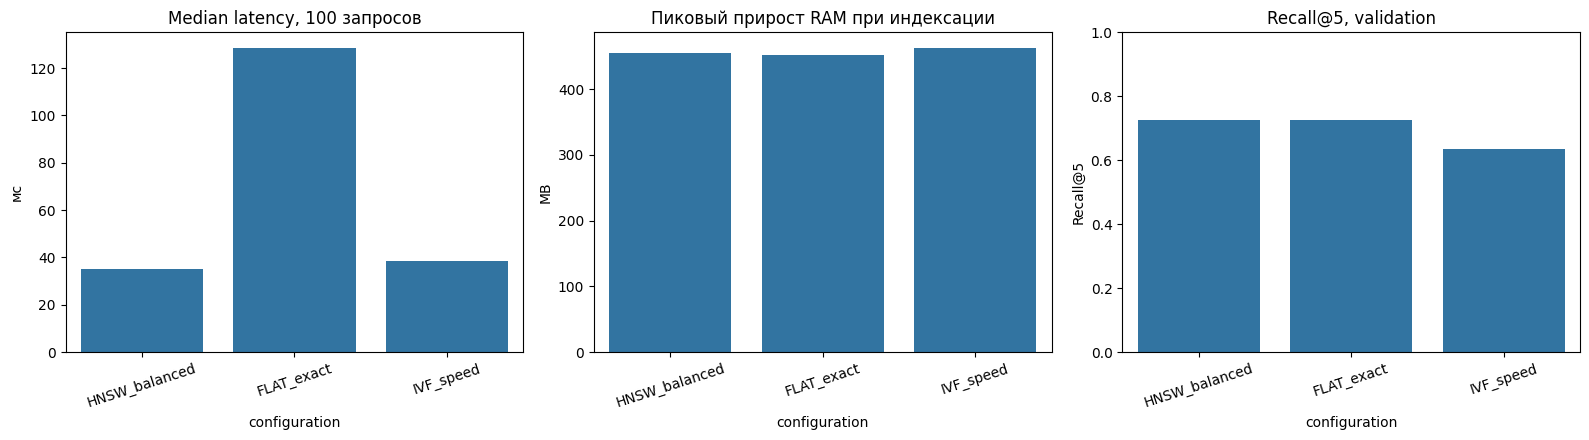

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(data=index_benchmark, x="configuration", y="median_query_ms", ax=axes[0])
axes[0].set_title("Median latency, 100 запросов")
axes[0].set_ylabel("мс")
sns.barplot(data=index_benchmark, x="configuration", y="peak_ram_delta_mb", ax=axes[1])
axes[1].set_title("Пиковый прирост RAM при индексации")
axes[1].set_ylabel("MB")
sns.barplot(data=index_benchmark, x="configuration", y="Recall@5", ax=axes[2])
axes[2].set_ylim(0, 1)
axes[2].set_title("Recall@5, validation")
axes[2].set_ylabel("Recall@5")
for ax in axes:
    ax.tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.savefig(OUT / "milvus_index_tradeoff.png", dpi=170, bbox_inches="tight")
plt.show()



 Фиксация индекса для scalability

In [ ]:
MAX_RECALL_LOSS = 0.02
flat_recall = float(
    index_benchmark.loc[index_benchmark["configuration"] == "FLAT_exact", "Recall@5"].iloc[0]
)
eligible = index_benchmark[
    index_benchmark["Recall@5"] >= flat_recall - MAX_RECALL_LOSS
].copy()
selected_row = eligible.sort_values(
    ["median_query_ms", "peak_ram_delta_mb", "indexing_seconds"],
    ascending=True,
).iloc[0]
SELECTED_INDEX_NAME = str(selected_row["configuration"])
SELECTED_INDEX_CONFIG = next(x for x in INDEX_CONFIGS if x["name"] == SELECTED_INDEX_NAME)

selection_card = {
    "selection_split": "validation",
    "quality_constraint": f"Recall@5 >= FLAT Recall@5 - {MAX_RECALL_LOSS}",
    "flat_recall_at_5": flat_recall,
    "selected_index": SELECTED_INDEX_NAME,
    "selected_configuration": SELECTED_INDEX_CONFIG,
}
(OUT / "selected_vector_index.json").write_text(
    json.dumps(selection_card, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(selection_card, ensure_ascii=False, indent=2))



{
  "selection_split": "validation",
  "quality_constraint": "Recall@5 >= FLAT Recall@5 - 0.02",
  "flat_recall_at_5": 0.7272727272727273,
  "selected_index": "HNSW_balanced",
  "selected_configuration": {
    "name": "HNSW_balanced",
    "index_type": "HNSW",
    "build_params": {
      "M": 16,
      "efConstruction": 128
    },
    "search_params": {
      "ef": 64
    }
  }
}


Scalability: 10% / 25% / 50% / 100% корпуса

In [ ]:
SCALE_FRACTIONS = [0.10, 0.25, 0.50, 1.00]
ordered_doc_ids = sorted(
    {d["doc_id"] for d in dedup_docs},
    key=lambda value: hashlib.sha256(value.encode("utf-8")).digest(),
)


def child_indices_for_fraction(fraction):
    n_docs = max(1, math.ceil(len(ordered_doc_ids) * fraction))
    selected_docs = set(ordered_doc_ids[:n_docs])
    indices = np.asarray(
        [i for i, child in enumerate(children) if child["doc_id"] in selected_docs],
        dtype=np.int64,
    )
    return n_docs, indices


scalability_rows = []
for fraction in SCALE_FRACTIONS:
    n_docs, indices = child_indices_for_fraction(fraction)
    print(f"\n=== {fraction:.0%}: {n_docs} документов, {len(indices)} children ===")
    run = build_milvus_index(
        SELECTED_INDEX_CONFIG,
        selected_indices=indices,
        db_suffix=f"scale_{int(fraction * 100):03d}",
    )
    latency = measure_query_latency(
        run["client"], run["collection_name"], SELECTED_INDEX_CONFIG
    )
    scalability_rows.append({
        "corpus_fraction": fraction,
        "documents": n_docs,
        "vectors": len(indices),
        "indexing_seconds": run["index_seconds"],
        "median_query_ms": latency["median_query_ms"],
        "p95_query_ms": latency["p95_query_ms"],
        "peak_ram_mb": run["peak_ram_mb"],
        "peak_ram_delta_mb": run["peak_ram_delta_mb"],
        "selected_index": SELECTED_INDEX_NAME,
    })
    run["client"].close()
    gc.collect()

scalability_results = pd.DataFrame(scalability_rows)
scalability_results.to_csv(OUT / "milvus_scalability.csv", index=False)
display(scalability_results.style.format({
    "corpus_fraction": "{:.0%}", "indexing_seconds": "{:.2f}",
    "median_query_ms": "{:.3f}", "p95_query_ms": "{:.3f}",
    "peak_ram_mb": "{:.1f}", "peak_ram_delta_mb": "{:.1f}",
}))




=== 10%: 50 документов, 1008 children ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!



=== 25%: 125 документов, 3239 children ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!



=== 50%: 250 документов, 6174 children ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!



=== 100%: 500 документов, 13295 children ===


ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


,corpus_fraction,documents,vectors,indexing_seconds,median_query_ms,p95_query_ms,peak_ram_mb,peak_ram_delta_mb,selected_index
0,10%,50,1008,1.69,42.622,49.499,3276.5,15.7,HNSW_balanced
1,25%,125,3239,4.79,24.612,26.928,3332.8,89.1,HNSW_balanced
2,50%,250,6174,9.97,27.665,54.910,3480.6,154.4,HNSW_balanced
3,100%,500,13295,19.88,33.025,65.555,3745.3,319.6,HNSW_balanced


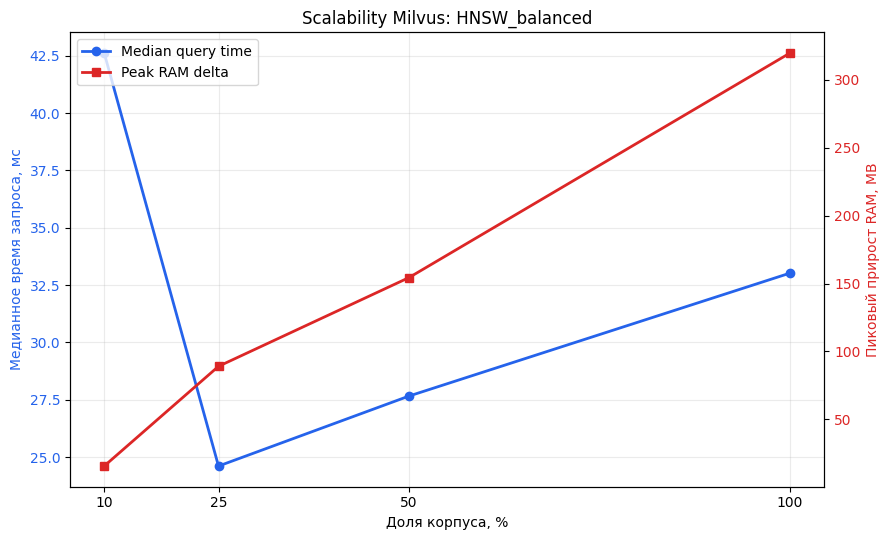

In [ ]:
fig, ax1 = plt.subplots(figsize=(9, 5.5))
x = scalability_results["corpus_fraction"] * 100
line1 = ax1.plot(
    x, scalability_results["median_query_ms"], marker="o", linewidth=2,
    color="#2563eb", label="Median query time",
)
ax1.set_xlabel("Доля корпуса, %")
ax1.set_ylabel("Медианное время запроса, мс", color="#2563eb")
ax1.tick_params(axis="y", labelcolor="#2563eb")
ax1.set_xticks([10, 25, 50, 100])
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
line2 = ax2.plot(
    x, scalability_results["peak_ram_delta_mb"], marker="s", linewidth=2,
    color="#dc2626", label="Peak RAM delta",
)
ax2.set_ylabel("Пиковый прирост RAM, MB", color="#dc2626")
ax2.tick_params(axis="y", labelcolor="#dc2626")

lines = line1 + line2
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")
plt.title(f"Scalability Milvus: {SELECTED_INDEX_NAME}")
plt.tight_layout()
plt.savefig(OUT / "milvus_scalability.png", dpi=170, bbox_inches="tight")
plt.show()



Сравнение эмбеддинг-моделей из ruMTEB

лёгкая	cointegrated/rubert-tiny2	29.4M
средняя	intfloat/multilingual-e5-base	278M
тяжёлая	BAAI/bge-m3	567M



In [ ]:
EMBEDDING_MODEL_CONFIGS = [
    {
        "tier": "light",
        "model": "cointegrated/rubert-tiny2",
        "published_parameters_m": 29.4,
        "rumteb_avg": 42.22,
        "rumteb_retrieval": 8.89,
        "document_prefix": "",
        "query_prefix": "",
        "max_seq_length": 512,
        "batch_size_gpu": 64,
        "batch_size_cpu": 16,
    },
    {
        "tier": "medium",
        "model": "intfloat/multilingual-e5-base",
        "published_parameters_m": 278.0,
        "rumteb_avg": 58.34,
        "rumteb_retrieval": 67.14,
        "document_prefix": "passage: ",
        "query_prefix": "query: ",
        "max_seq_length": 512,
        "batch_size_gpu": 32,
        "batch_size_cpu": 8,
    },
    {
        "tier": "heavy",
        "model": "BAAI/bge-m3",
        "published_parameters_m": 567.0,
        "rumteb_avg": 61.58,
        "rumteb_retrieval": 74.79,
        "document_prefix": "",
        "query_prefix": "",
        "max_seq_length": BGE_MAX_SEQ_LENGTH,
        "batch_size_gpu": BGE_BATCH_SIZE,
        "batch_size_cpu": 2,
    },
]

RUMTEB_SNAPSHOT_DATE = "2024-10-09"
EMBEDDING_QUERY_REPEATS = 100


def sync_accelerator():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def l2_normalize(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    if matrix.ndim == 1:
        matrix = matrix[None, :]
    norm = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norm, 1e-12)


def cached_snapshot_size_mb(repo_id, model):
    """Размер файлов snapshot; fallback — размер параметров в текущем dtype."""
    try:
        root = Path(snapshot_download(repo_id=repo_id, local_files_only=True))
        seen, total = set(), 0
        for path in root.rglob("*"):
            if not path.is_file():
                continue
            stat = path.resolve().stat()
            key = (stat.st_dev, stat.st_ino)
            if key not in seen:
                seen.add(key)
                total += stat.st_size
        return total / 1024**2, "HF snapshot"
    except Exception as exc:
        warnings.warn(f"Не удалось измерить HF snapshot для {repo_id}: {exc}")
        total = sum(p.nelement() * p.element_size() for p in model.parameters())
        return total / 1024**2, "weights in memory"


def encode_with_oom_backoff(model, texts, initial_batch_size, show_progress_bar):
    """Уменьшает batch только при CUDA OOM и возвращает фактический batch."""
    batch_size = int(initial_batch_size)
    while True:
        try:
            vectors = model.encode(
                texts,
                batch_size=batch_size,
                show_progress_bar=show_progress_bar,
                convert_to_numpy=True,
                normalize_embeddings=True,
            )
            return np.asarray(vectors, dtype=np.float32), batch_size
        except torch.cuda.OutOfMemoryError:
            if batch_size <= 1:
                raise
            batch_size = max(1, batch_size // 2)
            gc.collect()
            torch.cuda.empty_cache()
            warnings.warn(f"CUDA OOM: повтор с batch_size={batch_size}")


def exact_parent_ids(child_matrix, query_vector, limit=PRIMARY_K):
    scores = child_matrix @ np.asarray(query_vector, dtype=np.float32)
    parent_scores = np.full(len(parents), -np.inf, dtype=np.float32)
    np.maximum.at(parent_scores, CHILD_TO_PARENT, scores)
    n = min(limit, len(parent_scores))
    if n == 0:
        return []
    candidate_idx = np.argpartition(-parent_scores, n - 1)[:n]
    ordered = candidate_idx[np.argsort(-parent_scores[candidate_idx], kind="stable")]
    return [parents[int(idx)]["parent_id"] for idx in ordered]


def evaluate_embedding_model(child_matrix, question_vector_map, gold_records):
    positives = [x for x in gold_records if x["type"] != "negative"]
    rows = []
    for row in positives:
        retrieved = set(exact_parent_ids(child_matrix, question_vector_map[row["candidate_id"]]))
        found = [bool(retrieved & relevant) for relevant in RELEVANCE[row["candidate_id"]]]
        rows.append({
            "candidate_id": row["candidate_id"],
            "type": row["type"],
            "hit": float(any(found)),
            "recall": sum(found) / max(1, len(found)),
        })
    per_query = pd.DataFrame(rows)
    metrics = {
        "Hit@5": float(per_query["hit"].mean()),
        "Recall@5": float(per_query["recall"].mean()),
    }
    by_type = per_query.groupby("type", as_index=False).agg(
        n_questions=("candidate_id", "count"),
        **{"Hit@5": ("hit", "mean"), "Recall@5": ("recall", "mean")},
    )
    return metrics, per_query, by_type


def benchmark_single_embedder(config):
    model_name = config["model"]
    print(f"\n=== {config['tier']} | {model_name} ===")
    load_started = time.perf_counter()
    model = SentenceTransformer(model_name, device=DEVICE)
    detected_limit = getattr(model, "max_seq_length", None) or config["max_seq_length"]
    model.max_seq_length = min(config["max_seq_length"], int(detected_limit))
    load_seconds = time.perf_counter() - load_started

    actual_parameters_m = sum(p.numel() for p in model.parameters()) / 1e6
    model_size_mb, size_method = cached_snapshot_size_mb(model_name, model)
    start_batch = config["batch_size_gpu"] if DEVICE == "cuda" else config["batch_size_cpu"]

    document_texts = [
        config["document_prefix"] + f"{x['title']}\n{x['text']}" for x in children
    ]
    sync_accelerator()
    corpus_started = time.perf_counter()
    corpus_vectors, actual_batch = encode_with_oom_backoff(
        model, document_texts, start_batch, show_progress_bar=True
    )
    sync_accelerator()
    corpus_seconds = time.perf_counter() - corpus_started
    corpus_vectors = l2_normalize(corpus_vectors)

    all_questions = [config["query_prefix"] + x["question"] for x in ordered_gold]
    query_matrix, _ = encode_with_oom_backoff(
        model, all_questions, actual_batch, show_progress_bar=False
    )
    query_matrix = l2_normalize(query_matrix)
    query_map = {row["candidate_id"]: query_matrix[i] for i, row in enumerate(ordered_gold)}
    metrics, per_query, by_type = evaluate_embedding_model(
        corpus_vectors, query_map, validation_gold
    )

    latency_questions = [
        config["query_prefix"] + x["question"] for x in validation_gold
    ]
    if not latency_questions:
        raise ValueError("Validation split пуст — невозможно измерить latency.")

    _ = model.encode(
        [latency_questions[0]], batch_size=1, show_progress_bar=False,
        convert_to_numpy=True, normalize_embeddings=True,
    )
    sync_accelerator()

    embedding_ms, end_to_end_ms = [], []
    for i in range(EMBEDDING_QUERY_REPEATS):
        question = latency_questions[i % len(latency_questions)]
        sync_accelerator()
        started = time.perf_counter()
        qv = model.encode(
            [question], batch_size=1, show_progress_bar=False,
            convert_to_numpy=True, normalize_embeddings=True,
        )[0].astype(np.float32, copy=False)
        sync_accelerator()
        embedded_at = time.perf_counter()
        _ = exact_parent_ids(corpus_vectors, qv)
        finished_at = time.perf_counter()
        embedding_ms.append((embedded_at - started) * 1000)
        end_to_end_ms.append((finished_at - started) * 1000)

    by_type.insert(0, "model", model_name)
    per_query.insert(0, "model", model_name)
    result = {
        "tier": config["tier"],
        "model": model_name,
        "published_parameters_m": config["published_parameters_m"],
        "measured_parameters_m": actual_parameters_m,
        "model_size_mb": model_size_mb,
        "size_method": size_method,
        "vector_dimension": int(corpus_vectors.shape[1]),
        "max_seq_length": int(model.max_seq_length),
        "device": DEVICE,
        "batch_size": actual_batch,
        "corpus_child_chunks": len(children),
        "model_load_seconds": load_seconds,
        "corpus_embedding_seconds": corpus_seconds,
        "chunks_per_second": len(children) / max(corpus_seconds, 1e-12),
        "median_query_embedding_ms": float(np.median(embedding_ms)),
        "p95_query_embedding_ms": float(np.percentile(embedding_ms, 95)),
        "median_end_to_end_query_ms": float(np.median(end_to_end_ms)),
        "Hit@5": metrics["Hit@5"],
        "Recall@5": metrics["Recall@5"],
        "ruMTEB_Avg": config["rumteb_avg"],
        "ruMTEB_Retrieval": config["rumteb_retrieval"],
        "ruMTEB_snapshot": RUMTEB_SNAPSHOT_DATE,
    }

    del corpus_vectors, query_matrix, query_map, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, per_query, by_type

if "bge_model" in globals():
    del bge_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

embedding_rows, embedding_query_rows, embedding_type_rows = [], [], []
for embedding_config in EMBEDDING_MODEL_CONFIGS:
    result, per_query, by_type = benchmark_single_embedder(embedding_config)
    embedding_rows.append(result)
    embedding_query_rows.append(per_query)
    embedding_type_rows.append(by_type)

embedding_benchmark = pd.DataFrame(embedding_rows)
embedding_per_query = pd.concat(embedding_query_rows, ignore_index=True)
embedding_by_type = pd.concat(embedding_type_rows, ignore_index=True)

display_columns = [
    "tier", "model", "published_parameters_m", "model_size_mb",
    "corpus_embedding_seconds", "median_query_embedding_ms",
    "median_end_to_end_query_ms", "Hit@5", "Recall@5",
    "ruMTEB_Avg", "ruMTEB_Retrieval",
]
display(embedding_benchmark[display_columns].style.format({
    "published_parameters_m": "{:.1f}", "model_size_mb": "{:.1f}",
    "corpus_embedding_seconds": "{:.2f}",
    "median_query_embedding_ms": "{:.2f}",
    "median_end_to_end_query_ms": "{:.2f}",
    "Hit@5": "{:.3f}", "Recall@5": "{:.3f}",
    "ruMTEB_Avg": "{:.2f}", "ruMTEB_Retrieval": "{:.2f}",
}))
display(embedding_by_type.style.format({"Hit@5": "{:.3f}", "Recall@5": "{:.3f}"}))

embedding_benchmark.to_csv(OUT / "embedding_models_validation.csv", index=False)
embedding_per_query.to_csv(OUT / "embedding_models_per_query.csv", index=False)
embedding_by_type.to_csv(OUT / "embedding_models_by_type.csv", index=False)


=== light | cointegrated/rubert-tiny2 ===


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

...


=== heavy | BAAI/bge-m3 ===


/tmp/ipykernel_877/980260239.py:73: UserWarning: Не удалось измерить HF snapshot для BAAI/bge-m3: name 'snapshot_download' is not defined
  warnings.warn(f"Не удалось измерить HF snapshot для {repo_id}: {exc}")


Batches:   0%|          | 0/1662 [00:00<?, ?it/s]

,tier,model,published_parameters_m,model_size_mb,corpus_embedding_seconds,median_query_embedding_ms,median_end_to_end_query_ms,Hit@5,Recall@5,ruMTEB_Avg,ruMTEB_Retrieval
0,light,cointegrated/rubert-tiny2,29.4,111.4,14.24,5.11,6.02,0.273,0.227,42.22,8.89
1,medium,intfloat/multilingual-e5-base,278.0,1060.7,159.56,14.89,17.37,0.727,0.682,58.34,67.14
2,heavy,BAAI/bge-m3,567.0,2165.8,507.28,28.18,32.25,0.818,0.727,61.58,74.79


,model,type,n_questions,Hit@5,Recall@5
0,cointegrated/rubert-tiny2,abstract,3,0.000,0.000
1,cointegrated/rubert-tiny2,composite,3,0.333,0.167
2,cointegrated/rubert-tiny2,factual,5,0.400,0.400
3,intfloat/multilingual-e5-base,abstract,3,0.667,0.667
4,intfloat/multilingual-e5-base,composite,3,0.667,0.500
5,intfloat/multilingual-e5-base,factual,5,0.800,0.800
6,BAAI/bge-m3,abstract,3,0.667,0.667
7,BAAI/bge-m3,composite,3,1.000,0.667
8,BAAI/bge-m3,factual,5,0.800,0.800


Корреляция ruMTEB и качества на корпусе

Spearman ruMTEB Avg ↔ local Recall@5: 1.000
Spearman ruMTEB Retrieval ↔ local Recall@5: 1.000
Лучшая модель на local validation: BAAI/bge-m3
Порядок моделей на validation полностью совпал с ruMTEB Retrieval: позиция leaderboard положительно переносится на этот корпус.


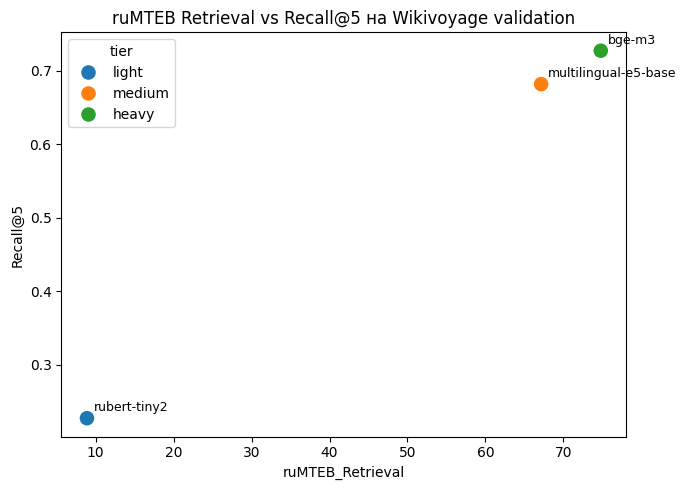

In [ ]:
def spearman_without_scipy(x, y):
    return float(pd.Series(x).rank().corr(pd.Series(y).rank(), method="pearson"))


rho_avg = spearman_without_scipy(
    embedding_benchmark["ruMTEB_Avg"], embedding_benchmark["Recall@5"]
)
rho_retrieval = spearman_without_scipy(
    embedding_benchmark["ruMTEB_Retrieval"], embedding_benchmark["Recall@5"]
)

leaderboard_order = embedding_benchmark.sort_values(
    "ruMTEB_Retrieval", ascending=False
)["model"].tolist()
local_order = embedding_benchmark.sort_values(
    ["Recall@5", "Hit@5"], ascending=False
)["model"].tolist()
same_order = leaderboard_order == local_order

correlation_summary = {
    "n_models": len(embedding_benchmark),
    "spearman_ruMTEB_Avg_vs_local_Recall@5": rho_avg,
    "spearman_ruMTEB_Retrieval_vs_local_Recall@5": rho_retrieval,
    "leaderboard_retrieval_order": leaderboard_order,
    "local_validation_order": local_order,
    "same_complete_order": same_order,
}
(OUT / "embedding_mteb_correlation.json").write_text(
    json.dumps(correlation_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

best_local = local_order[0]
if same_order:
    conclusion = (
        "Порядок моделей на validation полностью совпал с ruMTEB Retrieval: "
        "позиция leaderboard положительно переносится на этот корпус."
    )
elif rho_retrieval > 0:
    conclusion = (
        "Связь с ruMTEB Retrieval положительная, но порядок совпал не полностью. "
        "Leaderboard полезен как prior, однако финальный выбор требует domain gold."
    )
else:
    conclusion = (
        "Позиция в ruMTEB Retrieval не предсказала локальный Recall@5. Вероятные "
        "причины: Wikivoyage/MediaWiki-разметка, географические имена, короткий "
        "gold-набор и отличие нашей parent/child-метрики от задач ruMTEB."
    )

print(f"Spearman ruMTEB Avg ↔ local Recall@5: {rho_avg:.3f}")
print(f"Spearman ruMTEB Retrieval ↔ local Recall@5: {rho_retrieval:.3f}")
print("Лучшая модель на local validation:", best_local)
print(conclusion)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=embedding_benchmark, x="ruMTEB_Retrieval", y="Recall@5",
    hue="tier", s=130,
)
for _, row in embedding_benchmark.iterrows():
    plt.annotate(row["model"].split("/")[-1], (row["ruMTEB_Retrieval"], row["Recall@5"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.title("ruMTEB Retrieval vs Recall@5 на Wikivoyage validation")
plt.tight_layout()
plt.savefig(OUT / "embedding_mteb_vs_local_recall.png", dpi=160, bbox_inches="tight")
plt.show()

Три пайплайна поиска: Sparse, Dense и Hybrid

In [ ]:
EVAL_KS = (1, 5, 10)
FUSION_CANDIDATE_POOL = 50
RRF_K = 60
LATENCY_REPEATS = 100


def ranking_metrics_for_question(row, ranked_parent_ids, ranked_scores):
    top_score = float(ranked_scores[0]) if ranked_scores else -math.inf
    base = {
        "candidate_id": row["candidate_id"],
        "type": row["type"],
        "is_negative": row["type"] == "negative",
        "top_score": top_score,
    }
    if row["type"] == "negative":
        for k in EVAL_KS:
            base[f"Precision@{k}"] = math.nan
            base[f"Recall@{k}"] = math.nan
            base[f"NDCG@{k}"] = math.nan
        base.update({"AP": math.nan, "RR": math.nan})
        return base

    evidence_sets = RELEVANCE.get(row["candidate_id"], [])
    if not evidence_sets:
        for k in EVAL_KS:
            base[f"Precision@{k}"] = 0.0
            base[f"Recall@{k}"] = 0.0
            base[f"NDCG@{k}"] = 0.0
        base.update({"AP": 0.0, "RR": 0.0})
        return base

    uncovered = set(range(len(evidence_sets)))
    first_new_hit_flags = []
    reciprocal_rank = 0.0
    ap_sum = 0.0
    unique_hit_ranks = 0

    for rank, parent_id in enumerate(ranked_parent_ids, start=1):
        newly_covered = {
            idx for idx in uncovered if parent_id in evidence_sets[idx]
        }
        is_new_hit = bool(newly_covered)
        first_new_hit_flags.append(int(is_new_hit))
        if is_new_hit:
            uncovered -= newly_covered
            unique_hit_ranks += 1
            precision_at_rank = unique_hit_ranks / rank
            ap_sum += precision_at_rank
            if reciprocal_rank == 0.0:
                reciprocal_rank = 1.0 / rank

    for k in EVAL_KS:
        flags = first_new_hit_flags[:k]
        covered = set()
        for parent_id in ranked_parent_ids[:k]:
            covered.update(
                idx for idx, relevant in enumerate(evidence_sets)
                if parent_id in relevant
            )
        precision = sum(flags) / k
        recall = len(covered) / len(evidence_sets)
        dcg = sum(flag / math.log2(rank + 1) for rank, flag in enumerate(flags, 1))
        ideal_hits = min(len(evidence_sets), k)
        idcg = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_hits + 1))
        base[f"Precision@{k}"] = precision
        base[f"Recall@{k}"] = recall
        base[f"NDCG@{k}"] = dcg / idcg if idcg else 0.0

    base["AP"] = ap_sum / len(evidence_sets)
    base["RR"] = reciprocal_rank
    return base


def choose_abstention_threshold(per_query):
    """Максимизирует balanced accuracy: answer positives, abstain negatives."""
    finite = per_query[np.isfinite(per_query["top_score"])].copy()
    if finite.empty or finite["is_negative"].nunique() < 2:
        return -math.inf, math.nan
    scores = sorted(finite["top_score"].unique())
    candidates = [-math.inf]
    candidates += [(a + b) / 2 for a, b in zip(scores[:-1], scores[1:])]
    candidates += [math.inf]
    best = None
    for threshold in candidates:
        predicted_negative = finite["top_score"] < threshold
        negative_mask = finite["is_negative"]
        tnr = float(predicted_negative[negative_mask].mean())
        tpr = float((~predicted_negative[~negative_mask]).mean())
        balanced = (tnr + tpr) / 2
        candidate = (balanced, tpr, -threshold, threshold)
        if best is None or candidate[:3] > best[:3]:
            best = candidate
    return float(best[3]), float(best[0])


def evaluate_rankings(configuration, rankings, records, abstention_threshold=None):
    rows = []
    for row in records:
        ranked_ids, ranked_scores = rankings[row["candidate_id"]]
        rows.append(ranking_metrics_for_question(row, ranked_ids, ranked_scores))
    per_query = pd.DataFrame(rows)
    if abstention_threshold is None:
        threshold, balanced_accuracy = choose_abstention_threshold(per_query)
    else:
        threshold = float(abstention_threshold)
        predicted_negative = per_query["top_score"] < threshold
        negative_mask = per_query["is_negative"]
        tnr = float(predicted_negative[negative_mask].mean()) if negative_mask.any() else math.nan
        tpr = float((~predicted_negative[~negative_mask]).mean()) if (~negative_mask).any() else math.nan
        balanced_accuracy = float(np.nanmean([tnr, tpr]))
    per_query["abstained"] = per_query["top_score"] < threshold
    per_query["negative_correct"] = np.where(
        per_query["is_negative"], per_query["abstained"].astype(float), np.nan
    )

    positives = per_query[~per_query["is_negative"]]
    metrics = {"configuration": configuration}
    for k in EVAL_KS:
        for metric in ("Precision", "Recall", "NDCG"):
            metrics[f"{metric}@{k}"] = float(positives[f"{metric}@{k}"].mean())
    metrics.update({
        "MAP": float(positives["AP"].mean()),
        "MRR": float(positives["RR"].mean()),
        "NegativeAccuracy": float(
            per_query.loc[per_query["is_negative"], "negative_correct"].mean()
        ),
        "AbstentionThreshold": threshold,
        "BalancedAnswerAccuracy": balanced_accuracy,
    })

    by_type_rows = []
    for question_type, part in per_query.groupby("type"):
        item = {"configuration": configuration, "type": question_type, "n": len(part)}
        if question_type == "negative":
            item["NegativeAccuracy"] = float(part["negative_correct"].mean())
        else:
            for k in EVAL_KS:
                for metric in ("Precision", "Recall", "NDCG"):
                    item[f"{metric}@{k}"] = float(part[f"{metric}@{k}"].mean())
            item["MAP"] = float(part["AP"].mean())
            item["MRR"] = float(part["RR"].mean())
        by_type_rows.append(item)
    return metrics, per_query, pd.DataFrame(by_type_rows)


def top_indices_desc(scores, limit):
    scores = np.asarray(scores)
    n = min(limit, len(scores))
    if n == 0:
        return np.array([], dtype=np.int64)
    idx = np.argpartition(-scores, n - 1)[:n]
    return idx[np.argsort(-scores[idx], kind="stable")]

Sparse — BM25

k1 = [0.8, 1.2, 1.6, 2.0]: диапазон от сильного насыщения частоты слова до умеренного усиления повторов;

b = [0, 0.25, 0.5, 0.75, 1]: полный допустимый диапазон нормализации длины — от её отсутствия до максимальной коррекции.

In [ ]:
from rank_bm25 import BM25Okapi

BM25_K1_GRID = [0.8, 1.2, 1.6, 2.0]
BM25_B_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]


def sparse_tokenize(text):
    normalized = unicodedata.normalize("NFKC", str(text)).lower()
    return CONTENT_WORD_RE.findall(normalized)


parent_sparse_texts = [f"{p['title']}\n{p['text']}" for p in parents]
tokenized_parents = [sparse_tokenize(text) for text in parent_sparse_texts]
parent_ids_in_order = [p["parent_id"] for p in parents]


def bm25_rankings(model, records, limit=FUSION_CANDIDATE_POOL):
    rankings = {}
    for row in records:
        scores = np.asarray(model.get_scores(sparse_tokenize(row["question"])), dtype=np.float32)
        idx = top_indices_desc(scores, limit)
        rankings[row["candidate_id"]] = (
            [parent_ids_in_order[int(i)] for i in idx],
            [float(scores[int(i)]) for i in idx],
        )
    return rankings


def measure_bm25_latency(model, records, repeats=LATENCY_REPEATS):
    questions = [x["question"] for x in records]
    for q in questions[:min(10, len(questions))]:
        _ = top_indices_desc(model.get_scores(sparse_tokenize(q)), 10)
    times = []
    for i in range(repeats):
        q = questions[i % len(questions)]
        started = time.perf_counter_ns()
        _ = top_indices_desc(model.get_scores(sparse_tokenize(q)), 10)
        times.append((time.perf_counter_ns() - started) / 1e6)
    return float(np.median(times)), float(np.percentile(times, 95))


bm25_grid_rows = []
BM25_GRID_ARTIFACTS = {}
for k1 in BM25_K1_GRID:
    for b in BM25_B_GRID:
        name = f"BM25_k1={k1:.1f}_b={b:.2f}"
        with PeakRAM() as ram:
            started = time.perf_counter()
            model = BM25Okapi(tokenized_parents, k1=k1, b=b)
            index_seconds = time.perf_counter() - started
        rankings = bm25_rankings(model, validation_gold)
        metrics, per_query, by_type = evaluate_rankings(name, rankings, validation_gold)
        median_ms, p95_ms = measure_bm25_latency(model, validation_gold)
        row = {
            **metrics,
            "pipeline": "Sparse",
            "model": "BM25Okapi",
            "index": "inverted",
            "parameters": f"k1={k1:.1f}; b={b:.2f}",
            "k1": k1,
            "b": b,
            "indexing_seconds": index_seconds,
            "query_ms": median_ms,
            "p95_query_ms": p95_ms,
            "RAM_MB": ram.peak_mb,
            "RAM_delta_MB": ram.delta_mb,
        }
        bm25_grid_rows.append(row)
        BM25_GRID_ARTIFACTS[name] = {
            "model": model, "rankings": rankings,
            "per_query": per_query, "by_type": by_type,
        }

bm25_grid = pd.DataFrame(bm25_grid_rows).sort_values(
    ["NDCG@5", "Recall@5", "MAP", "query_ms"],
    ascending=[False, False, False, True],
).reset_index(drop=True)
BEST_BM25_NAME = str(bm25_grid.iloc[0]["configuration"])
BEST_BM25_K1 = float(bm25_grid.iloc[0]["k1"])
BEST_BM25_B = float(bm25_grid.iloc[0]["b"])

with PeakRAM() as best_bm25_ram:
    started = time.perf_counter()
    best_tokenized_parents = [sparse_tokenize(text) for text in parent_sparse_texts]
    BEST_BM25 = BM25Okapi(
        best_tokenized_parents, k1=BEST_BM25_K1, b=BEST_BM25_B
    )
    BEST_BM25_INDEX_SECONDS = time.perf_counter() - started

BEST_BM25_RANKINGS = bm25_rankings(BEST_BM25, validation_gold)
best_bm25_metrics, best_bm25_per_query, best_bm25_by_type = evaluate_rankings(
    BEST_BM25_NAME, BEST_BM25_RANKINGS, validation_gold
)
best_bm25_query_ms, best_bm25_p95_ms = measure_bm25_latency(
    BEST_BM25, validation_gold
)

best_mask = bm25_grid["configuration"] == BEST_BM25_NAME
bm25_grid.loc[best_mask, "indexing_seconds"] = BEST_BM25_INDEX_SECONDS
bm25_grid.loc[best_mask, "query_ms"] = best_bm25_query_ms
bm25_grid.loc[best_mask, "p95_query_ms"] = best_bm25_p95_ms
bm25_grid.loc[best_mask, "RAM_MB"] = best_bm25_ram.peak_mb
bm25_grid.loc[best_mask, "RAM_delta_MB"] = best_bm25_ram.delta_mb

bm25_grid.to_csv(OUT / "bm25_grid_validation.csv", index=False)
display(bm25_grid[[
    "configuration", "Precision@5", "Recall@5", "NDCG@5", "MAP", "MRR",
    "query_ms", "indexing_seconds",
]].style.format({
    "Precision@5": "{:.3f}", "Recall@5": "{:.3f}", "NDCG@5": "{:.3f}",
    "MAP": "{:.3f}", "MRR": "{:.3f}", "query_ms": "{:.3f}",
    "indexing_seconds": "{:.3f}",
}))
print(
    f"Лучший BM25: k1={BEST_BM25_K1:.1f}, b={BEST_BM25_B:.2f}; "
    f"полная индексация={BEST_BM25_INDEX_SECONDS:.3f} с, "
    f"median query={best_bm25_query_ms:.3f} мс."
)

BM25_GRID_ARTIFACTS = {BEST_BM25_NAME: BM25_GRID_ARTIFACTS[BEST_BM25_NAME]}
gc.collect()

,configuration,Precision@5,Recall@5,NDCG@5,MAP,MRR,query_ms,indexing_seconds
0,BM25_k1=2.0_b=1.00,0.127,0.500,0.435,0.404,0.473,5.850,0.880
1,BM25_k1=1.6_b=0.75,0.127,0.500,0.435,0.403,0.471,5.788,0.333
2,BM25_k1=1.2_b=1.00,0.127,0.500,0.435,0.410,0.443,6.117,0.324
3,BM25_k1=0.8_b=0.75,0.127,0.500,0.435,0.407,0.437,6.319,0.322
4,BM25_k1=0.8_b=1.00,0.127,0.500,0.435,0.406,0.437,6.580,0.330
5,BM25_k1=2.0_b=0.50,0.127,0.500,0.431,0.396,0.473,8.576,0.492
6,BM25_k1=2.0_b=0.75,0.127,0.500,0.430,0.396,0.466,6.038,0.575
7,BM25_k1=2.0_b=0.25,0.127,0.500,0.427,0.391,0.469,5.833,0.311
8,BM25_k1=1.6_b=0.50,0.127,0.500,0.424,0.389,0.463,5.883,0.311
9,BM25_k1=1.6_b=0.25,0.127,0.500,0.424,0.389,0.461,5.642,0.339


Лучший BM25: k1=2.0, b=1.00; полная индексация=0.880 с, median query=5.850 мс.


3731

 Dense — выбранные ранее модель и индекс

In [ ]:
selected_embedding_row = embedding_benchmark.sort_values(
    ["Recall@5", "Hit@5", "median_end_to_end_query_ms", "model_size_mb"],
    ascending=[False, False, True, True],
).iloc[0]
SELECTED_EMBEDDING_MODEL = str(selected_embedding_row["model"])
SELECTED_EMBEDDING_CONFIG = next(
    x for x in EMBEDDING_MODEL_CONFIGS if x["model"] == SELECTED_EMBEDDING_MODEL
)

def milvus_parent_search_scored(
    client, collection_name, query_vector, config, limit=FUSION_CANDIDATE_POOL
):
    result = client.search(
        collection_name=collection_name,
        anns_field="vector",
        data=[np.asarray(query_vector, dtype=np.float32).tolist()],
        limit=limit,
        group_by_field="parent_id",
        search_params={
            "metric_type": "COSINE",
            "params": config["search_params"],
        },
        output_fields=["parent_id"],
    )
    hits = result[0] if result else []
    ids, scores, seen = [], [], set()
    for hit in hits:
        entity = hit.get("entity", {}) if isinstance(hit, dict) else {}
        parent_id = entity.get("parent_id") or hit.get("parent_id")
        if not parent_id or parent_id in seen:
            continue
        seen.add(parent_id)
        ids.append(parent_id)
        scores.append(float(hit.get("distance", hit.get("score", 0.0))))
        if len(ids) >= limit:
            break
    return ids, scores


PIPELINE_DENSE_RUN = build_milvus_index(
    SELECTED_INDEX_CONFIG, db_suffix="three_pipelines"
)


def dense_rankings(records, limit=FUSION_CANDIDATE_POOL):
    return {
        row["candidate_id"]: milvus_parent_search_scored(
            PIPELINE_DENSE_RUN["client"],
            PIPELINE_DENSE_RUN["collection_name"],
            question_vectors[row["candidate_id"]],
            SELECTED_INDEX_CONFIG,
            limit=limit,
        )
        for row in records
    }


DENSE_NAME = f"Dense|{SELECTED_EMBEDDING_MODEL}|{SELECTED_INDEX_NAME}"
DENSE_RANKINGS = dense_rankings(validation_gold)
dense_metrics, dense_per_query, dense_by_type = evaluate_rankings(
    DENSE_NAME, DENSE_RANKINGS, validation_gold
)

pipeline_embedding_model = SentenceTransformer(
    SELECTED_EMBEDDING_MODEL, device=DEVICE
)
detected_limit = getattr(pipeline_embedding_model, "max_seq_length", None) or SELECTED_EMBEDDING_CONFIG["max_seq_length"]
pipeline_embedding_model.max_seq_length = min(
    SELECTED_EMBEDDING_CONFIG["max_seq_length"], int(detected_limit)
)


def encode_pipeline_query(question):
    text = SELECTED_EMBEDDING_CONFIG["query_prefix"] + question
    return pipeline_embedding_model.encode(
        [text], batch_size=1, show_progress_bar=False,
        convert_to_numpy=True, normalize_embeddings=True,
    )[0].astype(np.float32, copy=False)


def measure_dense_latency(records, repeats=LATENCY_REPEATS):
    questions = [x["question"] for x in records]
    for q in questions[:min(10, len(questions))]:
        qv = encode_pipeline_query(q)
        _ = milvus_parent_search_scored(
            PIPELINE_DENSE_RUN["client"], PIPELINE_DENSE_RUN["collection_name"],
            qv, SELECTED_INDEX_CONFIG, limit=10,
        )
    times = []
    for i in range(repeats):
        q = questions[i % len(questions)]
        sync_accelerator()
        started = time.perf_counter_ns()
        qv = encode_pipeline_query(q)
        _ = milvus_parent_search_scored(
            PIPELINE_DENSE_RUN["client"], PIPELINE_DENSE_RUN["collection_name"],
            qv, SELECTED_INDEX_CONFIG, limit=10,
        )
        sync_accelerator()
        times.append((time.perf_counter_ns() - started) / 1e6)
    return float(np.median(times)), float(np.percentile(times, 95))


dense_query_ms, dense_p95_ms = measure_dense_latency(validation_gold)
DENSE_RAM_MB = max(
    float(PIPELINE_DENSE_RUN["peak_ram_mb"]), process_tree_rss_mb()
)

display(pd.DataFrame([{
    "model": SELECTED_EMBEDDING_MODEL,
    "index": SELECTED_INDEX_NAME,
    "index_params": json.dumps(SELECTED_INDEX_CONFIG, ensure_ascii=False),
    "Precision@5": dense_metrics["Precision@5"],
    "Recall@5": dense_metrics["Recall@5"],
    "NDCG@5": dense_metrics["NDCG@5"],
    "MAP": dense_metrics["MAP"],
    "MRR": dense_metrics["MRR"],
    "query_ms": dense_query_ms,
}]))

ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


,model,index,index_params,Precision@5,Recall@5,NDCG@5,MAP,MRR,query_ms
0,BAAI/bge-m3,HNSW_balanced,"{""name"": ""HNSW_balanced"", ""index_type"": ""HNSW""...",0.218182,0.727273,0.69765,0.667708,0.753367,77.612229


Hybrid — RRF и weighted linear combination

In [ ]:
ALPHA_GRID = [round(x / 10, 1) for x in range(11)]


def minmax_score_map(ids, scores):
    if not ids:
        return {}
    values = np.asarray(scores, dtype=np.float32)
    lo, hi = float(values.min()), float(values.max())
    if hi - lo < 1e-12:
        normalized = np.ones_like(values)
    else:
        normalized = (values - lo) / (hi - lo)
    return {doc_id: float(score) for doc_id, score in zip(ids, normalized)}


def fuse_rrf(sparse_result, dense_result, rrf_k=RRF_K):
    fused = defaultdict(float)
    for ids, _scores in (sparse_result, dense_result):
        for rank, doc_id in enumerate(ids, start=1):
            fused[doc_id] += 1.0 / (rrf_k + rank)
    ordered = sorted(fused.items(), key=lambda x: (-x[1], x[0]))
    return [x[0] for x in ordered], [float(x[1]) for x in ordered]


def fuse_weighted(sparse_result, dense_result, alpha):
    sparse_map = minmax_score_map(*sparse_result)
    dense_map = minmax_score_map(*dense_result)
    candidates = set(sparse_map) | set(dense_map)
    fused = {
        doc_id: alpha * dense_map.get(doc_id, 0.0)
        + (1.0 - alpha) * sparse_map.get(doc_id, 0.0)
        for doc_id in candidates
    }
    ordered = sorted(fused.items(), key=lambda x: (-x[1], x[0]))
    return [x[0] for x in ordered], [float(x[1]) for x in ordered]


def fused_rankings(records, method, alpha=None):
    output = {}
    for row in records:
        qid = row["candidate_id"]
        sparse_result = BEST_BM25_RANKINGS[qid]
        dense_result = DENSE_RANKINGS[qid]
        output[qid] = (
            fuse_rrf(sparse_result, dense_result)
            if method == "RRF"
            else fuse_weighted(sparse_result, dense_result, alpha)
        )
    return output


HYBRID_ARTIFACTS = {}
hybrid_rows = []

rrf_name = f"Hybrid_RRF_k={RRF_K}"
rrf_rankings = fused_rankings(validation_gold, "RRF")
rrf_metrics, rrf_per_query, rrf_by_type = evaluate_rankings(
    rrf_name, rrf_rankings, validation_gold
)
hybrid_rows.append({
    **rrf_metrics, "pipeline": "Hybrid-RRF", "fusion": f"RRF(k={RRF_K})",
    "alpha": math.nan,
})
HYBRID_ARTIFACTS[rrf_name] = {
    "method": "RRF", "alpha": None, "rankings": rrf_rankings,
    "per_query": rrf_per_query, "by_type": rrf_by_type,
}

for alpha in ALPHA_GRID:
    name = f"Hybrid_weighted_alpha={alpha:.1f}"
    rankings = fused_rankings(validation_gold, "weighted", alpha=alpha)
    metrics, per_query, by_type = evaluate_rankings(name, rankings, validation_gold)
    hybrid_rows.append({
        **metrics, "pipeline": "Hybrid-weighted",
        "fusion": "minmax weighted", "alpha": alpha,
    })
    HYBRID_ARTIFACTS[name] = {
        "method": "weighted", "alpha": alpha, "rankings": rankings,
        "per_query": per_query, "by_type": by_type,
    }

hybrid_grid = pd.DataFrame(hybrid_rows)
weighted_candidates = hybrid_grid[
    (hybrid_grid["pipeline"] == "Hybrid-weighted")
    & (hybrid_grid["alpha"] > 0.0)
    & (hybrid_grid["alpha"] < 1.0)
]
best_weighted = weighted_candidates.sort_values(
    ["NDCG@5", "Recall@5", "MAP"], ascending=False
).iloc[0]
BEST_ALPHA = float(best_weighted["alpha"])

hybrid_final_candidates = pd.concat([
    hybrid_grid[hybrid_grid["pipeline"] == "Hybrid-RRF"],
    weighted_candidates,
], ignore_index=True)
best_hybrid_row = hybrid_final_candidates.sort_values(
    ["NDCG@5", "Recall@5", "MAP"], ascending=False
).iloc[0]
BEST_HYBRID_NAME = str(best_hybrid_row["configuration"])
BEST_HYBRID = HYBRID_ARTIFACTS[BEST_HYBRID_NAME]


def retrieve_raw_components(question):
    sparse_scores = np.asarray(
        BEST_BM25.get_scores(sparse_tokenize(question)), dtype=np.float32
    )
    sparse_idx = top_indices_desc(sparse_scores, FUSION_CANDIDATE_POOL)
    sparse_result = (
        [parent_ids_in_order[int(i)] for i in sparse_idx],
        [float(sparse_scores[int(i)]) for i in sparse_idx],
    )
    qv = encode_pipeline_query(question)
    dense_result = milvus_parent_search_scored(
        PIPELINE_DENSE_RUN["client"], PIPELINE_DENSE_RUN["collection_name"],
        qv, SELECTED_INDEX_CONFIG, limit=FUSION_CANDIDATE_POOL,
    )
    return sparse_result, dense_result


def measure_hybrid_latency(method, alpha=None, repeats=LATENCY_REPEATS):
    questions = [x["question"] for x in validation_gold]
    for q in questions[:min(10, len(questions))]:
        sparse_result, dense_result = retrieve_raw_components(q)
        _ = fuse_rrf(sparse_result, dense_result) if method == "RRF" else fuse_weighted(
            sparse_result, dense_result, alpha
        )
    times = []
    for i in range(repeats):
        q = questions[i % len(questions)]
        sync_accelerator()
        started = time.perf_counter_ns()
        sparse_result, dense_result = retrieve_raw_components(q)
        _ = fuse_rrf(sparse_result, dense_result) if method == "RRF" else fuse_weighted(
            sparse_result, dense_result, alpha
        )
        sync_accelerator()
        times.append((time.perf_counter_ns() - started) / 1e6)
    return float(np.median(times)), float(np.percentile(times, 95))


rrf_query_ms, rrf_p95_ms = measure_hybrid_latency("RRF")
weighted_query_ms, weighted_p95_ms = measure_hybrid_latency(
    "weighted", BEST_ALPHA
)
HYBRID_RAM_MB = process_tree_rss_mb()

hybrid_grid["query_ms"] = np.where(
    hybrid_grid["pipeline"] == "Hybrid-RRF", rrf_query_ms, weighted_query_ms
)
hybrid_grid["p95_query_ms"] = np.where(
    hybrid_grid["pipeline"] == "Hybrid-RRF", rrf_p95_ms, weighted_p95_ms
)
hybrid_grid["RAM_MB"] = HYBRID_RAM_MB
hybrid_grid.to_csv(OUT / "hybrid_grid_validation.csv", index=False)

display(hybrid_grid[[
    "configuration", "alpha", "Precision@5", "Recall@5", "NDCG@5",
    "MAP", "MRR", "NegativeAccuracy", "query_ms",
]].sort_values(["NDCG@5", "Recall@5"], ascending=False).style.format({
    "alpha": "{:.1f}", "Precision@5": "{:.3f}", "Recall@5": "{:.3f}",
    "NDCG@5": "{:.3f}", "MAP": "{:.3f}", "MRR": "{:.3f}",
    "NegativeAccuracy": "{:.3f}", "query_ms": "{:.3f}",
}))
print(f"Лучший weighted alpha={BEST_ALPHA:.1f}")
print(f"Финальный hybrid по validation: {BEST_HYBRID_NAME}")

,configuration,alpha,Precision@5,Recall@5,NDCG@5,MAP,MRR,NegativeAccuracy,query_ms
7,Hybrid_weighted_alpha=0.6,0.6,0.218,0.727,0.737,0.713,0.821,0.500,265.452
8,Hybrid_weighted_alpha=0.7,0.7,0.218,0.727,0.737,0.715,0.821,0.500,265.452
9,Hybrid_weighted_alpha=0.8,0.8,0.218,0.727,0.709,0.679,0.776,0.500,265.452
10,Hybrid_weighted_alpha=0.9,0.9,0.218,0.727,0.702,0.671,0.761,0.500,265.452
11,Hybrid_weighted_alpha=1.0,1.0,0.218,0.727,0.698,0.668,0.753,0.000,265.452
6,Hybrid_weighted_alpha=0.5,0.5,0.200,0.682,0.685,0.664,0.775,0.333,265.452
0,Hybrid_RRF_k=60,nan,0.182,0.636,0.635,0.612,0.742,0.333,265.759
5,Hybrid_weighted_alpha=0.4,0.4,0.182,0.636,0.629,0.615,0.693,0.500,265.452
4,Hybrid_weighted_alpha=0.3,0.3,0.182,0.636,0.615,0.583,0.688,0.500,265.452
3,Hybrid_weighted_alpha=0.2,0.2,0.164,0.591,0.539,0.507,0.581,0.667,265.452


Лучший weighted alpha=0.7
Финальный hybrid по validation: Hybrid_weighted_alpha=0.7


Итоговая сравнительная таблица для КТ 4

In [ ]:
comparison_rows = []
for _, row in bm25_grid.iterrows():
    comparison_rows.append({
        "Configuration": row["configuration"],
        "Pipeline": "Sparse",
        "Model": "BM25Okapi",
        "Index": "inverted",
        "Parameters": row["parameters"],
        **{f"{m}@{k}": row[f"{m}@{k}"] for k in EVAL_KS for m in ("Precision", "Recall", "NDCG")},
        "MAP": row["MAP"], "MRR": row["MRR"],
        "Query_ms": row["query_ms"], "RAM_MB": row["RAM_MB"],
        "Indexing_s": row["indexing_seconds"],
        "NegativeAccuracy": row["NegativeAccuracy"],
    })

comparison_rows.append({
    "Configuration": DENSE_NAME,
    "Pipeline": "Dense",
    "Model": SELECTED_EMBEDDING_MODEL,
    "Index": SELECTED_INDEX_NAME,
    "Parameters": json.dumps(SELECTED_INDEX_CONFIG, ensure_ascii=False),
    **{f"{m}@{k}": dense_metrics[f"{m}@{k}"] for k in EVAL_KS for m in ("Precision", "Recall", "NDCG")},
    "MAP": dense_metrics["MAP"], "MRR": dense_metrics["MRR"],
    "Query_ms": dense_query_ms, "RAM_MB": DENSE_RAM_MB,
    "Indexing_s": PIPELINE_DENSE_RUN["index_seconds"],
    "NegativeAccuracy": dense_metrics["NegativeAccuracy"],
})

for _, row in hybrid_grid.iterrows():
    comparison_rows.append({
        "Configuration": row["configuration"],
        "Pipeline": row["pipeline"],
        "Model": f"BM25 + {SELECTED_EMBEDDING_MODEL}",
        "Index": f"inverted + {SELECTED_INDEX_NAME}",
        "Parameters": row["fusion"] + (
            "" if pd.isna(row["alpha"]) else f"; alpha={row['alpha']:.1f}"
        ),
        **{f"{m}@{k}": row[f"{m}@{k}"] for k in EVAL_KS for m in ("Precision", "Recall", "NDCG")},
        "MAP": row["MAP"], "MRR": row["MRR"],
        "Query_ms": row["query_ms"], "RAM_MB": row["RAM_MB"],
        "Indexing_s": BEST_BM25_INDEX_SECONDS + PIPELINE_DENSE_RUN["index_seconds"],
        "NegativeAccuracy": row["NegativeAccuracy"],
    })

all_pipeline_configurations = pd.DataFrame(comparison_rows)
all_pipeline_configurations.to_csv(
    OUT / "all_pipeline_configurations_validation.csv", index=False
)

required_comparison_columns = [
    "Configuration", "Pipeline", "Model", "Index", "Parameters",
    "Precision@5", "Recall@5", "NDCG@5", "MAP", "MRR", "Query_ms", "RAM_MB",
]
display(all_pipeline_configurations[required_comparison_columns].sort_values(
    ["NDCG@5", "Recall@5", "MAP"], ascending=False
).style.format({
    "Precision@5": "{:.3f}", "Recall@5": "{:.3f}", "NDCG@5": "{:.3f}",
    "MAP": "{:.3f}", "MRR": "{:.3f}", "Query_ms": "{:.3f}", "RAM_MB": "{:.1f}",
}))

best_sparse_final = all_pipeline_configurations[
    all_pipeline_configurations["Configuration"] == BEST_BM25_NAME
].iloc[0]
dense_final = all_pipeline_configurations[
    all_pipeline_configurations["Configuration"] == DENSE_NAME
].iloc[0]
best_hybrid_final = all_pipeline_configurations[
    all_pipeline_configurations["Configuration"] == BEST_HYBRID_NAME
].iloc[0]
family_finalists = pd.DataFrame([best_sparse_final, dense_final, best_hybrid_final])
all_k_columns = [
    "Configuration", "Pipeline",
    *[f"{metric}@{k}" for k in EVAL_KS for metric in ("Precision", "Recall", "NDCG")],
    "MAP", "MRR", "NegativeAccuracy",
]
display(family_finalists[all_k_columns].style.format({
    column: "{:.3f}" for column in all_k_columns
    if column not in {"Configuration", "Pipeline"}
}))
recommended_row = family_finalists.sort_values(
    ["NDCG@5", "Recall@5", "MAP", "Query_ms"],
    ascending=[False, False, False, True],
).iloc[0]

KT4_RECOMMENDATION = {
    "selection_split": "validation",
    "rule": "max NDCG@5, then Recall@5, then MAP, then min query latency",
    "configuration": str(recommended_row["Configuration"]),
    "pipeline": str(recommended_row["Pipeline"]),
    "model": str(recommended_row["Model"]),
    "index": str(recommended_row["Index"]),
    "parameters": str(recommended_row["Parameters"]),
    "Precision@5": float(recommended_row["Precision@5"]),
    "Recall@5": float(recommended_row["Recall@5"]),
    "NDCG@5": float(recommended_row["NDCG@5"]),
    "MAP": float(recommended_row["MAP"]),
    "MRR": float(recommended_row["MRR"]),
    "Query_ms": float(recommended_row["Query_ms"]),
    "reason": (
        "Лучшее ранжирование на validation по заранее заданному правилу; "
        "test не использовался для выбора."
    ),
}
(OUT / "kt4_recommended_retriever.json").write_text(
    json.dumps(KT4_RECOMMENDATION, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Рекомендация для КТ 4:")
print(json.dumps(KT4_RECOMMENDATION, ensure_ascii=False, indent=2))

,Configuration,Pipeline,Model,Index,Parameters,Precision@5,Recall@5,NDCG@5,MAP,MRR,Query_ms,RAM_MB
29,Hybrid_weighted_alpha=0.7,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.7,0.218,0.727,0.737,0.715,0.821,265.452,3828.2
28,Hybrid_weighted_alpha=0.6,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.6,0.218,0.727,0.737,0.713,0.821,265.452,3828.2
30,Hybrid_weighted_alpha=0.8,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.8,0.218,0.727,0.709,0.679,0.776,265.452,3828.2
31,Hybrid_weighted_alpha=0.9,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.9,0.218,0.727,0.702,0.671,0.761,265.452,3828.2
20,Dense|BAAI/bge-m3|HNSW_balanced,Dense,BAAI/bge-m3,HNSW_balanced,"{""name"": ""HNSW_balanced"", ""index_type"": ""HNSW"", ""build_params"": {""M"": 16, ""efConstruction"": 128}, ""search_params"": {""ef"": 64}}",0.218,0.727,0.698,0.668,0.753,77.612,3828.8
32,Hybrid_weighted_alpha=1.0,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=1.0,0.218,0.727,0.698,0.668,0.753,265.452,3828.2
27,Hybrid_weighted_alpha=0.5,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.5,0.200,0.682,0.685,0.664,0.775,265.452,3828.2
21,Hybrid_RRF_k=60,Hybrid-RRF,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,RRF(k=60),0.182,0.636,0.635,0.612,0.742,265.759,3828.2
26,Hybrid_weighted_alpha=0.4,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.4,0.182,0.636,0.629,0.615,0.693,265.452,3828.2
25,Hybrid_weighted_alpha=0.3,Hybrid-weighted,BM25 + BAAI/bge-m3,inverted + HNSW_balanced,minmax weighted; alpha=0.3,0.182,0.636,0.615,0.583,0.688,265.452,3828.2


,Configuration,Pipeline,Precision@1,Recall@1,NDCG@1,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,MAP,MRR,NegativeAccuracy
0,BM25_k1=2.0_b=1.00,Sparse,0.364,0.318,0.364,0.127,0.500,0.435,0.073,0.545,0.455,0.404,0.473,0.167
20,Dense|BAAI/bge-m3|HNSW_balanced,Dense,0.727,0.545,0.727,0.218,0.727,0.698,0.109,0.727,0.698,0.668,0.753,0.333
29,Hybrid_weighted_alpha=0.7,Hybrid-weighted,0.818,0.591,0.818,0.218,0.727,0.737,0.109,0.727,0.737,0.715,0.821,0.500


Рекомендация для КТ 4:
{
  "selection_split": "validation",
  "rule": "max NDCG@5, then Recall@5, then MAP, then min query latency",
  "configuration": "Hybrid_weighted_alpha=0.7",
  "pipeline": "Hybrid-weighted",
  "model": "BM25 + BAAI/bge-m3",
  "index": "inverted + HNSW_balanced",
  "parameters": "minmax weighted; alpha=0.7",
  "Precision@5": 0.21818181818181825,
  "Recall@5": 0.7272727272727273,
  "NDCG@5": 0.7366827000789968,
  "MAP": 0.7152811537838276,
  "MRR": 0.8209366391184574,
  "Query_ms": 265.45248100000003,
  "reason": "Лучшее ранжирование на validation по заранее заданному правилу; test не использовался для выбора."
}
